<a href="https://colab.research.google.com/github/gianayee06/GitHub-Workshop/blob/main/Assignments/Assignment_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment 3



# Question 1

You have two circles:

$$ \begin{align}
[x -2]^2 + y^2 &= 4 \\
x^2 + [y-3]^2 &= 4
\end{align} $$

and you want to find where they cross.

a) Write out $\vec{f}({\vec{x}})$

$$
\mathbf{f}(\mathbf{x}) =
\begin{bmatrix}
(x-2)^2 + y^2 - 4 \\
x^2 + (y-3)^2 - 4
\end{bmatrix},
\qquad
\mathbf{x} =
\begin{bmatrix}
x \\
y
\end{bmatrix}
$$

b) Write out the Jacobian $J(\vec{x})$

$$
J(\mathbf{x}) =
\begin{bmatrix}
2(x-2) & 2y \\
2x & 2(y-3)
\end{bmatrix}
$$

c) Write a Newton-Raphson method and use it to find where the circles cross (*Don't use a nonlinear solver package - show the algorithm down to the linear solver!*)

{implementation, answer x2}

In [4]:
import numpy as np

# Calculate both circle equations at the point (x, y)
def f(point):
    x, y = point

    return np.array([
        (x - 2)**2 + y**2 - 4,
        x**2 + (y - 3)**2 - 4
    ])


# Calculate the Jacobian at our current point
def J(point):
    x, y = point

    return np.array([
        [2*(x - 2), 2*y],
        [2*x, 2*(y - 3)]
    ])


def newton_raphson(initial_guess, tolerance=1e-8, max_iterations=100):
    point = np.array(initial_guess, dtype=float)

    for i in range(max_iterations):
        f_value = f(point)

        # Stop if both equations are close enough to zero
        if np.max(np.abs(f_value)) < tolerance:
            return point

        # Calculate how much to change x and y
        change = np.linalg.solve(J(point), -f_value)

        # Update our guess and continue the loop
        point = point + change

    raise RuntimeError("Didn't converge within the iteration limit")


# Run the function using two starting guesses
intersection_1 = newton_raphson([0, 1])
intersection_2 = newton_raphson([2, 2])

print("First intersection:", intersection_1)
print("Second intersection:", intersection_2)


First intersection: [0.27942331 1.01961554]
Second intersection: [1.72057669 1.98038446]


# Question 2:

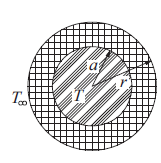

A wire carrying an electric current is surrounded by rubber insulation of outer radius $r$. The resistance of the wire generates heat, which is conducted through the insulation and convected into the surrounding air. The temperature of the wire can be shown to be:

$$ T = \frac{q}{2 \pi} \bigg[ \frac{ln(r/a)}{k} + \frac{1}{hr} \bigg] + T_\infty $$

where

- q = rate of heat generation in wire = 50 W/m
- a = radius of wire = 5mm
- k = thermal conductivity of rubber = 0.16 W/m · K
- h = convective heat-transfer coefficient = 20 W/m2 · K
- T∞ = ambient temperature = 280 K

Find $r$ that minimizes $T$

{method, imlementation, answer}


In [5]:
import numpy as np

# Given values, using metres and kelvin
q = 50          # Heat generated per metre of wire (W/m)
a = 0.005       # Wire radius: 5 mm converted to metres
k = 0.16        # Thermal conductivity of the rubber (W/(m K))
h = 20          # Heat-transfer coefficient (W/(m² K))
T_air = 280     # Surrounding air temperature (K)


# Calculate the wire temperature for an outer insulation radius r
def temperature(r):
    # np.log calculates the natural logarithm
    return (q / (2*np.pi)) * (
        np.log(r/a) / k + 1 / (h*r)
    ) + T_air


# First derivative: tells us how temperature changes with radius
# We want this slope to equal zero
def slope(r):
    return (q / (2*np.pi)) * (
        1 / (k*r) - 1 / (h*r**2)
    )


# Second derivative: tells us how the slope changes with radius
def curvature(r):
    return (q / (2*np.pi)) * (
        -1 / (k*r**2) + 2 / (h*r**3)
    )


# Use Newton-Raphson to find where the temperature's slope is zero
def find_radius(guess, tolerance=1e-8, max_iterations=100):
    r = guess

    # Repeat until the slope is close enough to zero
    for i in range(max_iterations):

        # abs ignores the sign when checking how close we are to zero
        if abs(slope(r)) < tolerance:
            return r

        # Improve our radius estimate using Newton-Raphson
        r = r - slope(r) / curvature(r)

    # Report an error if the method does not converge
    raise RuntimeError("Did not converge within the iteration limit")


# Start with an outer radius of 6 mm, larger than the 5 mm wire
r_min = find_radius(0.006)

# Calculate the temperature at the radius we found
T_min = temperature(r_min)

# Display the radius in millimetres and temperature in kelvin
print("Outer radius (mm):", round(r_min * 1000, 3))
print("Minimum temperature (K):", round(T_min, 2))

# Positive curvature confirms this stationary point is a minimum
print("Is this a minimum?", curvature(r_min) > 0)

Outer radius (mm): 8.0
Minimum temperature (K): 353.11
Is this a minimum? True


# Question 3:

{Method, answer}

Given the data in (T, k) columns,

In [2]:
import numpy as np
data = np.array([[2.73000000e+02, 4.45900132e+03],
       [2.76030303e+02, 4.41776331e+03],
       [2.79060606e+02, 7.02912764e+03],
       [2.82090909e+02, 8.07233255e+03],
       [2.85121212e+02, 1.35655353e+04],
       [2.88151515e+02, 1.53935301e+04],
       [2.91181818e+02, 1.66518521e+04],
       [2.94212121e+02, 2.57056205e+04],
       [2.97242424e+02, 2.80402378e+04],
       [3.00272727e+02, 3.52850720e+04],
       [3.03303030e+02, 2.53348206e+04],
       [3.06333333e+02, 6.20422294e+04],
       [3.09363636e+02, 5.65720969e+04],
       [3.12393939e+02, 8.94469023e+04],
       [3.15424242e+02, 9.65941942e+04],
       [3.18454545e+02, 1.14139663e+05],
       [3.21484848e+02, 1.00384893e+05],
       [3.24515152e+02, 1.60315046e+05],
       [3.27545455e+02, 1.75487522e+05],
       [3.30575758e+02, 2.79200552e+05],
       [3.33606061e+02, 2.83492579e+05],
       [3.36636364e+02, 2.19343286e+05],
       [3.39666667e+02, 3.46339717e+05],
       [3.42696970e+02, 3.29907107e+05],
       [3.45727273e+02, 2.99334626e+05],
       [3.48757576e+02, 4.85091915e+05],
       [3.51787879e+02, 7.28675595e+05],
       [3.54818182e+02, 9.91612106e+05],
       [3.57848485e+02, 9.39914377e+05],
       [3.60878788e+02, 1.46925677e+06],
       [3.63909091e+02, 1.46126057e+06],
       [3.66939394e+02, 1.35738053e+06],
       [3.69969697e+02, 1.14736966e+06],
       [3.73000000e+02, 2.10254656e+06],
       [3.76030303e+02, 1.12017395e+06],
       [3.79060606e+02, 2.34226319e+06],
       [3.82090909e+02, 2.22858410e+06],
       [3.85121212e+02, 3.26613076e+06],
       [3.88151515e+02, 3.68055559e+06],
       [3.91181818e+02, 2.37869512e+06],
       [3.94212121e+02, 4.10021974e+06],
       [3.97242424e+02, 3.84314791e+06],
       [4.00272727e+02, 6.46893402e+06],
       [4.03303030e+02, 5.35422811e+06],
       [4.06333333e+02, 7.73962115e+06],
       [4.09363636e+02, 8.41409713e+06],
       [4.12393939e+02, 7.81006766e+06],
       [4.15424242e+02, 8.35579617e+06],
       [4.18454545e+02, 1.03669786e+07],
       [4.21484848e+02, 1.02992887e+07],
       [4.24515152e+02, 6.39189417e+06],
       [4.27545455e+02, 1.36405449e+07],
       [4.30575758e+02, 1.49410729e+07],
       [4.33606061e+02, 2.09149077e+07],
       [4.36636364e+02, 2.14703032e+07],
       [4.39666667e+02, 2.11464887e+07],
       [4.42696970e+02, 2.60359855e+07],
       [4.45727273e+02, 3.19593647e+07],
       [4.48757576e+02, 2.84547486e+07],
       [4.51787879e+02, 2.98421720e+07],
       [4.54818182e+02, 3.54693846e+07],
       [4.57848485e+02, 4.17941703e+07],
       [4.60878788e+02, 4.65948030e+07],
       [4.63909091e+02, 5.74740135e+07],
       [4.66939394e+02, 4.12282427e+07],
       [4.69969697e+02, 6.43295352e+07],
       [4.73000000e+02, 6.78921367e+07],
       [4.76030303e+02, 6.87155479e+07],
       [4.79060606e+02, 6.70678776e+07],
       [4.82090909e+02, 6.23342574e+07],
       [4.85121212e+02, 9.48617775e+07],
       [4.88151515e+02, 9.34710486e+07],
       [4.91181818e+02, 8.25781385e+07],
       [4.94212121e+02, 1.02888832e+08],
       [4.97242424e+02, 9.99071191e+07],
       [5.00272727e+02, 1.01319698e+08],
       [5.03303030e+02, 1.32602108e+08],
       [5.06333333e+02, 1.31923942e+08],
       [5.09363636e+02, 1.00146518e+08],
       [5.12393939e+02, 1.48398130e+08],
       [5.15424242e+02, 2.01128065e+08],
       [5.18454545e+02, 2.25792703e+08],
       [5.21484848e+02, 1.99863590e+08],
       [5.24515152e+02, 2.47074414e+08],
       [5.27545455e+02, 2.08548654e+08],
       [5.30575758e+02, 1.83449792e+08],
       [5.33606061e+02, 2.58856094e+08],
       [5.36636364e+02, 3.10038100e+08],
       [5.39666667e+02, 3.58956357e+08],
       [5.42696970e+02, 3.21512830e+08],
       [5.45727273e+02, 4.30773903e+08],
       [5.48757576e+02, 4.39179856e+08],
       [5.51787879e+02, 4.57110476e+08],
       [5.54818182e+02, 3.75292342e+08],
       [5.57848485e+02, 3.97574548e+08],
       [5.60878788e+02, 4.57516936e+08],
       [5.63909091e+02, 2.63845055e+08],
       [5.66939394e+02, 4.59249219e+08],
       [5.69969697e+02, 5.23677345e+08],
       [5.73000000e+02, 7.51098462e+08]])

In [6]:
import numpy as np
from scipy.optimize import curve_fit
import plotly.graph_objects as go

# Take the temperature from the first column of every row
T_data = data[:, 0]

# Take the measured rate constant from the second column
k_data = data[:, 1]

# Ideal gas constant in J/(mol K)
R = 8.314


# Define the equation we want to fit to the data
# T is temperature; A, B, and E are the unknown parameters
def reaction_rate(T, A, B, E):
    # np.exp calculates e raised to the expression inside
    return (A + B*T) * np.exp(-E / (R*T))


# Starting estimates for A, B, and E, in that order
# These are rough estimates informed by the reference solution
initial_guess = [1e14, -1e11, 55000]

# Adjust A, B, and E to make the curve fit the measurements
# p0 supplies the starting estimates
# maxfev sets the maximum number of function evaluations
parameters, covariance = curve_fit(
    reaction_rate,
    T_data,
    k_data,
    p0=initial_guess,
    maxfev=10000
)

# Separate the three fitted parameters
A, B, E = parameters

# Print the fitted values
print("A =", A)
print("B =", B)
print("E (J/mol) =", E)


# Create 100 evenly spaced temperatures across our data range
T_plot = np.linspace(T_data.min(), T_data.max(), 100)

# Calculate the fitted rate constant at each temperature
k_plot = reaction_rate(T_plot, A, B, E)

# Create an empty graph
fig = go.Figure()

# Show the original measurements as dots
fig.add_trace(go.Scatter(
    x=T_data,
    y=k_data,
    mode='markers',
    name='Measured data'
))

# Show the fitted equation as a smooth line
fig.add_trace(go.Scatter(
    x=T_plot,
    y=k_plot,
    mode='lines',
    name='Modified Arrhenius fit'
))

# Add the graph title and axis labels
fig.update_layout(
    title='Modified Arrhenius Fit',
    xaxis_title='Temperature (K)',
    yaxis_title='Rate constant k'
)

# Display the graph
fig.show()

A = 141634529172311.47
B = -133639709121.49121
E (J/mol) = 55400.54332053193


fit a modified Arrhenius curve of the form:

$$k = [A +B T]e^{\frac{-E}{RT}} $$

where $R$ is the Ideal gas constant.


